In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/kenilprajapati/antropy-python-library-wheel-file/antropy-0.1.9-py3-none-any.whl
/kaggle/input/datasets/danizo/eeg-dataset-for-adhd/adhdata.csv


In [2]:
!pip install /kaggle/input/datasets/kenilprajapati/antropy-python-library-wheel-file/antropy-0.1.9-py3-none-any.whl

Processing /kaggle/input/datasets/kenilprajapati/antropy-python-library-wheel-file/antropy-0.1.9-py3-none-any.whl


In [3]:
import numpy as np
import pandas as pd
import antropy as ant
import pywt
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from scipy.signal import welch, hilbert, csd

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# --- Constants ---
SELECTED_CHANNELS = ['F3', 'F4', 'Fz', 'P3', 'P4', 'Pz', 'O1', 'O2']
SF = 128
WINDOW_LEN = 4 * SF

In [4]:
def calculate_wpli(sig1, sig2):
    """Calculates Weighted Phase Lag Index between two signals."""
    f, Pxy = csd(sig1, sig2, fs=128, nperseg=128)
    imag_pxy = np.imag(Pxy)
    return np.abs(np.mean(imag_pxy)) / (np.mean(np.abs(imag_pxy)) + 1e-6)

def extract_wavelet_features(sig):
    """Calculates Wavelet Energy across 4 levels."""
    coeffs = pywt.wavedec(sig, 'db4', level=4)
    return [np.sum(np.square(c)) for c in coeffs]

def extract_all_features(eeg_data, sf=128):
    all_features = []
    ch_metrics = {}
    
    for i, ch_name in enumerate(SELECTED_CHANNELS):
        sig = eeg_data[i]
        
        # A. Statistical Features
        all_features.extend([np.mean(sig), np.std(sig), np.var(sig), skew(sig), kurtosis(sig)])
        
        # B. Bandpower (Welch)
        freqs, psd = welch(sig, sf, nperseg=sf)
        def bp(low, high):
            idx = np.logical_and(freqs >= low, freqs <= high)
            return np.trapezoid(psd[idx], freqs[idx])
        
        t, a, b = bp(4, 8), bp(8, 13), bp(13, 30)
        ch_metrics[ch_name] = {'t': t, 'a': a, 'b': b}
        all_features.extend([t, a, b, t/(b + 1e-6)])
        
        # C. Nonlinear Complexity
        hfd = ant.higuchi_fd(sig)
        se = ant.spectral_entropy(sig, sf, method='welch')
        ch_metrics[ch_name].update({'hfd': hfd, 'se': se})
        all_features.extend([hfd, se, ant.sample_entropy(sig)])
        
        # D. Wavelet Energies
        all_features.extend(extract_wavelet_features(sig))

    # E. Connectivity (Fz vs Pz)
    idx_fz = SELECTED_CHANNELS.index('Fz')
    idx_pz = SELECTED_CHANNELS.index('Pz')
    all_features.append(calculate_wpli(eeg_data[idx_fz], eeg_data[idx_pz]))

    # F. Ratios & Interactions
    fz_comp_ratio = ch_metrics['Fz']['hfd'] / (ch_metrics['Fz']['t'] + 1e-6)
    fp_interact = ch_metrics['Fz']['hfd'] * ch_metrics['Pz']['se']
    faa = np.log(ch_metrics['F4']['a'] + 1e-6) - np.log(ch_metrics['F3']['a'] + 1e-6)
    
    all_features.extend([fz_comp_ratio, fp_interact, faa])
    return np.array(all_features)

In [5]:
# Load Data
df = pd.read_csv("/kaggle/input/datasets/danizo/eeg-dataset-for-adhd/adhdata.csv")
subjects = df['ID'].unique()
X, y, groups = [], [], []

# Process Windows
for sub in tqdm(subjects, desc="Step 1/2: Processing Subjects"):
    sub_df = df[df['ID'] == sub]
    label = 1 if "ADHD" in str(sub_df['Class'].iloc[0]).upper() else 0
    raw_data = sub_df[SELECTED_CHANNELS].values 
    
    for start in range(0, len(raw_data) - WINDOW_LEN, WINDOW_LEN):
        win = raw_data[start : start + WINDOW_LEN].T 
        X.append(extract_all_features(win, SF))
        y.append(label)
        groups.append(sub)

X, y, groups = np.array(X), np.array(y), np.array(groups)

Step 1/2: Processing Subjects: 100%|██████████| 121/121 [01:43<00:00,  1.16it/s]


In [6]:
# Pipeline Setup
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)), 
    ('svc', SVC(probability=True, class_weight='balanced'))
])

param_grid = {
    'selector__k': [40, 80, 120],
    'svc__C': [1, 10, 50],
    'svc__kernel': ['rbf']
}

# Search
gkf = GroupKFold(n_splits=5)
print("\nStep 2/2: Training & CV Search...")
grid = GridSearchCV(pipeline, param_grid, cv=gkf, verbose=1, n_jobs=-1)
grid.fit(X, y, groups=groups)

# Generate CV Predictions
y_pred_cv = cross_val_predict(grid.best_estimator_, X, y, groups=groups, cv=gkf)


Step 2/2: Training & CV Search...
Fitting 5 folds for each of 9 candidates, totalling 45 fits



--- Final Cross-Validated Subject-Level Report ---
              precision    recall  f1-score   support

           0       0.83      0.82      0.82        60
           1       0.82      0.84      0.83        61

    accuracy                           0.83       121
   macro avg       0.83      0.83      0.83       121
weighted avg       0.83      0.83      0.83       121

Total Misclassified Subjects: 21


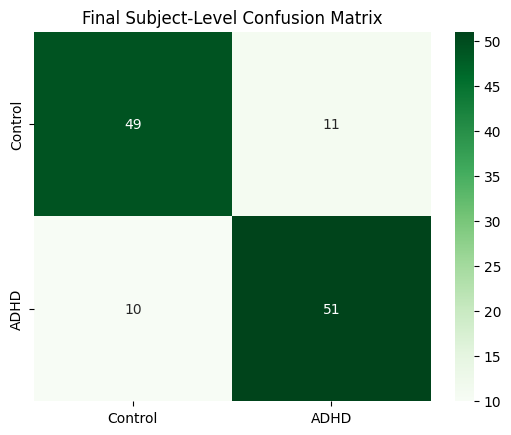

In [7]:
# 1. Subject-Level Prediction (Soft Voting)
subject_results = []
for train_idx, test_idx in gkf.split(X, y, groups=groups):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    model = grid.best_estimator_
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_test)[:, 1]
    
    fold_df = pd.DataFrame({'Subject': groups[test_idx], 'Prob': probs, 'True': y_test})
    subject_results.append(fold_df.groupby('Subject').agg({'Prob': 'mean', 'True': 'first'}))

# 2. Final Metrics
final_cv_results = pd.concat(subject_results)
final_cv_results['Pred'] = (final_cv_results['Prob'] >= 0.5).astype(int)

print("\n--- Final Cross-Validated Subject-Level Report ---")
print(classification_report(final_cv_results['True'], final_cv_results['Pred']))
print(f"Total Misclassified Subjects: {sum(final_cv_results['True'] != final_cv_results['Pred'])}")

# 3. Visualization
cm = confusion_matrix(final_cv_results['True'], final_cv_results['Pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Control', 'ADHD'], yticklabels=['Control', 'ADHD'])
plt.title('Final Subject-Level Confusion Matrix')
plt.show()

Fold 1 Subject-Level Accuracy: 0.7917
Fold 2 Subject-Level Accuracy: 0.8400
Fold 3 Subject-Level Accuracy: 0.7917
Fold 4 Subject-Level Accuracy: 0.8333
Fold 5 Subject-Level Accuracy: 0.8750

FINAL SUBJECT-LEVEL CV SCORE: 0.8263 ± 0.0316


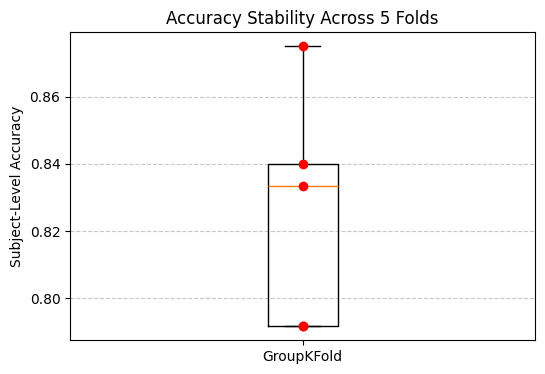

In [8]:
from sklearn.metrics import accuracy_score

# 1. Initialize list for individual fold scores
fold_scores = []

# 2. Calculate accuracy for each fold based on the subject_results list
for i, fold_df in enumerate(subject_results):
    # Determine predictions for this fold (threshold = 0.5)
    y_true_fold = fold_df['True']
    y_pred_fold = (fold_df['Prob'] >= 0.5).astype(int)
    
    # Calculate score
    score = accuracy_score(y_true_fold, y_pred_fold)
    fold_scores.append(score)
    print(f"Fold {i+1} Subject-Level Accuracy: {score:.4f}")

# 3. Final Statistical Summary
mean_cv = np.mean(fold_scores)
std_cv = np.std(fold_scores)

print("\n" + "="*45)
print(f"FINAL SUBJECT-LEVEL CV SCORE: {mean_cv:.4f} ± {std_cv:.4f}")
print("="*45)

# 4. Optional: Stability Visualization
plt.figure(figsize=(6, 4))
plt.boxplot(fold_scores)
plt.scatter([1]*len(fold_scores), fold_scores, color='red', zorder=3)
plt.title('Accuracy Stability Across 5 Folds')
plt.ylabel('Subject-Level Accuracy')
plt.xticks([1], ['GroupKFold'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [9]:
# 1. Filter for rows where the Prediction does not match the True Label
misclassified_df = final_cv_results[final_cv_results['True'] != final_cv_results['Pred']].copy()

# 2. Sort by how "wrong" the model was (Confidence)
# For a False Positive (True=0, Pred=1), high Prob is a 'strong' error.
# For a False Negative (True=1, Pred=0), low Prob is a 'strong' error.
misclassified_df['Error_Magnitude'] = abs(misclassified_df['Prob'] - misclassified_df['True'])
misclassified_df = misclassified_df.sort_values(by='Error_Magnitude', ascending=False)

# 3. Display the results
print(f"--- Detailed Analysis of {len(misclassified_df)} Misclassified Subjects ---")
print(misclassified_df[['True', 'Pred', 'Prob']])

# 4. Summary of Error Types
fps = len(misclassified_df[(misclassified_df['True'] == 0) & (misclassified_df['Pred'] == 1)])
fns = len(misclassified_df[(misclassified_df['True'] == 1) & (misclassified_df['Pred'] == 0)])

print(f"\nBreakdown:")
print(f"False Positives (Control labeled as ADHD): {fps}")
print(f"False Negatives (ADHD labeled as Control): {fns}")

--- Detailed Analysis of 21 Misclassified Subjects ---
         True  Pred      Prob
Subject                      
v59p        0     1  0.967047
v298        0     1  0.954049
v15p        1     0  0.057042
v8p         1     0  0.076167
v6p         1     0  0.086013
v12p        1     0  0.092649
v140        0     1  0.885189
v14p        1     0  0.119444
v1p         1     0  0.120113
v138        0     1  0.858407
v149        0     1  0.855041
v134        0     1  0.842399
v190        1     0  0.163050
v45p        0     1  0.742386
v143        0     1  0.662056
v55p        0     1  0.619411
v19p        1     0  0.381219
v196        1     0  0.387176
v112        0     1  0.584440
v44p        0     1  0.531834
v246        1     0  0.498357

Breakdown:
False Positives (Control labeled as ADHD): 11
False Negatives (ADHD labeled as Control): 10


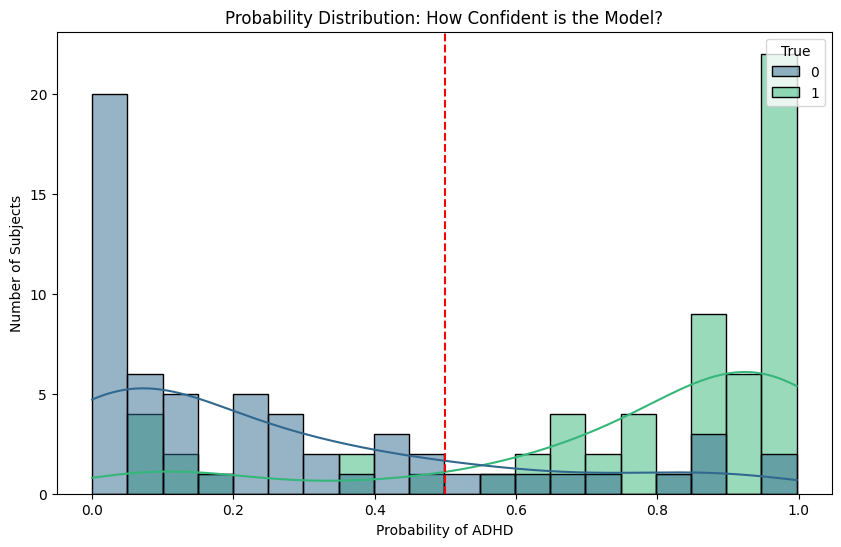

In [10]:
plt.figure(figsize=(10, 6))
sns.histplot(data=final_cv_results, x='Prob', hue='True', bins=20, kde=True, palette='viridis')
plt.axvline(0.5, color='red', linestyle='--')
plt.title('Probability Distribution: How Confident is the Model?')
plt.xlabel('Probability of ADHD')
plt.ylabel('Number of Subjects')
plt.show()

In [11]:
import joblib

# 1. Path where you want to save the model
model_filename = 'adhd_eeg_model_v1.pkl'

# 2. Save the best estimator found by GridSearchCV
# This saves the entire pipeline (Scaler + Selector + SVC)
joblib.dump(grid.best_estimator_, model_filename)

print(f"✅ Model saved successfully as {model_filename}")

✅ Model saved successfully as adhd_eeg_model_v1.pkl


In [12]:
# Select a high-confidence ADHD subject
test_subject_id = 'v15p' 
sample_df = df[df['ID'] == test_subject_id]

# Save it for local testing
sample_filename = f'test_sample_{test_subject_id}.csv'
sample_df.to_csv(sample_filename, index=False)

print(f"✅ Extracted high-confidence sample for {test_subject_id}")

✅ Extracted high-confidence sample for v15p
